# Volume 14, workshop chapter 7: From data to conjecture (Python companion)

The experimental loop of the chapter, run for real: digits of $\pi$ from the middle (Proposition 7.2), the LLL algorithm written from the proof of Theorem 7.5, the rediscovery of the BBP formula (Theorem 7.1) from numbers alone, Ramanujan's almost integer, and Pólya's false conjecture. The computer-science application is a classic of cryptanalysis: **breaking a knapsack cryptosystem with LLL** (Lagarias and Odlyzko, 1985). Exercises first, solutions at the end. Requires `numpy` and `mpmath`.

In [1]:
import math, numpy as np
from fractions import Fraction
import mpmath as mp
rng = np.random.default_rng(7)

## Exercises

**P7.1 (★) Digits from the middle.** Implement Proposition 7.2 and print the hexadecimal digits of $\pi$ from position $10^6+1$ on. Check the method on positions $1$ to $40$ against `mpmath`.

**P7.2 (★★) LLL.** Implement the algorithm of Theorem 7.5 in exact rational arithmetic. Run it on the basis $(13,9),(5,4)$ of Figure 7.1, then on random $10$-dimensional integer bases, and compare $|b_1|$ with the bound $2^{(n-1)/2}\lambda_1$ (estimate $\lambda_1$ by brute force in small dimension). Count the exchanges and compare with $\log_{4/3}D_0$.

**P7.3 (★★) Rediscovering BBP.** Compute $\pi,S_1,\dots,S_8$ to $60$ digits and search for an integer relation with the lattice of Proposition 7.6. Do you find the BBP relation? Then try $\pi$ with $S_1,S_4,S_5,S_6$ only. Finally solve Exercise 7.5 the same way.

**P7.4 (★) Ramanujan's constant.** Compute $e^{\pi\sqrt{163}}$ to $40$ digits, and compare $640320^3+744-e^{\pi\sqrt{163}}$ with $196884e^{-\pi\sqrt{163}}$ (Exercise 7.6). Which other $d$ give almost integers $e^{\pi\sqrt d}$?

**P7.5 (★★) Pólya's conjecture.** Sieve $\lambda(n)$ up to $10^7$, plot $L(x)/\sqrt x$, and check that $L(x)\le0$ for $2\le x\le10^7$. How close does $L$ come to $0$? (The first positive value is at $906\,150\,257$.) Check the identity of Exercise 7.7 for $x\le10^4$.

**P7.6 (★★★) CS application: breaking a knapsack.** In the Merkle–Hellman scheme (1978), a message $m\in\{0,1\}^n$ is encrypted as $s=\sum m_ia_i$ for a public list $a_1,\dots,a_n$ that looks random. Decrypting without the secret key is a subset-sum problem, NP-hard in general. Lagarias and Odlyzko observed that when the $a_i$ are large ("low density" $n/\log_2\max a_i<0.64$), the message is a very short vector of the lattice spanned by the rows of
$$\begin{pmatrix}I_n & N a^{\mathsf T}\\ 0 & -Ns\end{pmatrix}.$$
Generate random instances with $n=20$ and $a_i<2^{60}$, and recover $m$ by LLL. How does the success rate change with the density?

## Solutions

**P7.1.** Modular exponentiation is Python's `pow(16, e, m)`; the tail is summed with floats.

In [2]:
def T(j, d):
    s = 0.0
    for k in range(d + 1):
        m = 8 * k + j
        s = (s + pow(16, d - k, m) / m) % 1.0
    k, t = d + 1, 0.0
    while True:
        term = 16.0 ** (d - k) / (8 * k + j)
        if term < 1e-17: break
        t += term; k += 1
    return (s + t) % 1.0
def hexdigits(d, count=8):
    x = (4 * T(1, d) - 2 * T(4, d) - T(5, d) - T(6, d)) % 1.0
    out = ""
    for _ in range(count):
        x *= 16; out += "0123456789ABCDEF"[int(x)]; x -= int(x)
    return out
mp.mp.dps = 60
ref = ""
x = mp.pi - 3
for _ in range(40):
    x *= 16; ref += "0123456789ABCDEF"[int(x)]; x -= int(x)
mine = "".join(hexdigits(d, 1) for d in range(40))
print("positions 1-40 agree:", mine == ref, ref)
import time; t0 = time.time()
print("from position 10^6 on:", hexdigits(10**6 - 1, 8), f"({time.time()-t0:.1f}s)")

positions 1-40 agree: True 243F6A8885A308D313198A2E03707344A4093822


from position 10^6 on: 26C65E52 (3.7s)


The digits `26C65E52` starting at position $10^6$ agree with the table of Bailey, Borwein and Plouffe. Eight digits is about what double precision allows at this depth, as the chapter estimated.

**P7.2.** A direct transcription of the proof, recomputing Gram–Schmidt each time (slow but transparent).

In [3]:
def gram_schmidt(B):
    n = len(B); Bs = []; mu = [[Fraction(0)] * n for _ in range(n)]
    for i in range(n):
        v = [Fraction(x) for x in B[i]]
        for j in range(i):
            mu[i][j] = sum(Fraction(a) * b for a, b in zip(B[i], Bs[j])) / sum(b * b for b in Bs[j])
            v = [a - mu[i][j] * b for a, b in zip(v, Bs[j])]
        Bs.append(v)
    return Bs, mu
def lll(B, delta=Fraction(3, 4)):
    B = [list(map(int, b)) for b in B]; n = len(B); k = 1; swaps = 0
    while k < n:
        for j in range(k - 1, -1, -1):
            Bs, mu = gram_schmidt(B)
            q = round(mu[k][j])
            if q: B[k] = [a - q * b for a, b in zip(B[k], B[j])]
        Bs, mu = gram_schmidt(B)
        nk = sum(x * x for x in Bs[k]); nk1 = sum(x * x for x in Bs[k - 1])
        if nk >= (delta - mu[k][k - 1] ** 2) * nk1:
            k += 1
        else:
            B[k], B[k - 1] = B[k - 1], B[k]; swaps += 1; k = max(k - 1, 1)
    return B, swaps
print(lll([[13, 9], [5, 4]]))
def D(B):
    Bs, _ = gram_schmidt(B); prod = Fraction(1); d = Fraction(1)
    for i in range(len(B) - 1):
        d *= sum(x * x for x in Bs[i]); prod *= d
    return prod
for trial in range(3):
    n = 6
    B = [[int(x) for x in rng.integers(-50, 51, n)] for _ in range(n)]
    Bred, sw = lll(B)
    b1 = math.sqrt(sum(x * x for x in Bred[0]))
    # brute-force lambda_1 over small coefficient vectors of the reduced basis
    import itertools
    lam = min(math.sqrt(sum(x * x for x in np.dot(c, Bred))) for c in itertools.product(range(-2, 3), repeat=n) if any(c))
    print(f"|b1| = {b1:.2f}, lambda1 <= {lam:.2f}, bound 2^((n-1)/2) lambda1 = {2**2.5*lam:.1f}; swaps {sw}, log_(4/3) D0 = {math.log(float(D(B)))/math.log(4/3):.0f}")

([[-1, 2], [3, 1]], 3)
|b1| = 48.27, lambda1 <= 46.89, bound 2^((n-1)/2) lambda1 = 265.3; swaps 11, log_(4/3) D0 = 426


|b1| = 50.69, lambda1 <= 50.69, bound 2^((n-1)/2) lambda1 = 286.7; swaps 4, log_(4/3) D0 = 436
|b1| = 26.10, lambda1 <= 23.87, bound 2^((n-1)/2) lambda1 = 135.1; swaps 21, log_(4/3) D0 = 408


In practice $|b_1|$ is equal or very close to the shortest vector, far below the worst-case factor $2^{(n-1)/2}$, and the number of exchanges is a small fraction of the bound $\log_{4/3}D_0$: the bound is what the proof can guarantee, not what typically happens.

**P7.3.** Scale by $N=10^{50}$ and reduce.

In [4]:
mp.mp.dps = 80
def S(j): return mp.nsum(lambda k: mp.mpf(16) ** (-k) / (8 * k + j), [0, mp.inf])
def find_relation(xs, N=10**50):
    n = len(xs)
    B = [[1 if i == j else 0 for j in range(n)] + [int(mp.nint(N * xs[i]))] for i in range(n)]
    Bred, _ = lll(B)
    return Bred[0][:n]
xs = [mp.pi] + [S(j) for j in range(1, 9)]
print("pi, S1..S8:", find_relation(xs))
print("pi, S1, S4, S5, S6:", find_relation([mp.pi, S(1), S(4), S(5), S(6)]))
a = mp.sqrt(2) + mp.sqrt(3)
print("1, a, ..., a^4:", find_relation([a ** k for k in range(5)], N=10**30))

pi, S1..S8: [1, -4, 0, 0, 2, 1, 1, 0, 0]


pi, S1, S4, S5, S6: [1, -4, 2, 1, 1]
1, a, ..., a^4: [1, 0, -10, 0, 1]


Even with all nine numbers, the first vector is $(1,-4,0,0,2,1,1,0,0)$: the BBP relation $\pi=4S_1-2S_4-S_5-S_6$ comes out of the haystack by itself. With the five relevant numbers it is found at once. (In other searches the first vector can be a relation among the $S_j$ alone, or a combination of several relations: an integer relation search answers the question you ask, so choose the numbers well.) For $\sqrt2+\sqrt3$ the answer is $x^4-10x^2+1$, which Exercise 7.5 proves.

**P7.4.**

In [5]:
mp.mp.dps = 50
e163 = mp.e ** (mp.pi * mp.sqrt(163))
print(e163)
print("640320^3+744 - e^(pi sqrt163) =", mp.mpf(640320) ** 3 + 744 - e163, " vs 196884 e^(-pi sqrt163) =", 196884 / e163)
for d in (19, 43, 67, 163, 58, 37):
    v = mp.e ** (mp.pi * mp.sqrt(d)); print(d, mp.nstr(v, 25), " distance to nearest integer:", mp.nstr(abs(v - mp.nint(v)), 3))

262537412640768743.99999999999925007259719818568887
640320^3+744 - e^(pi sqrt163) = 0.00000000000074992740280181431113187545786369255111591223231648  vs 196884 e^(-pi sqrt163) = 0.00000000000074992740280181462295933336589025562258030309891696
19 885479.7776801543194975379  distance to nearest integer: 0.222
43 884736743.9997774660349067  distance to nearest integer: 0.000223
67 147197952743.9999986624542  distance to nearest integer: 1.34e-6
163 262537412640768744.0  distance to nearest integer: 7.5e-13
58 24591257751.99999982221324  distance to nearest integer: 1.78e-7
37 199148647.9999780465518568  distance to nearest integer: 2.2e-5


The two numbers agree to many digits; the rest of the error is the next term of the $q$-expansion. The other Heegner numbers $19,43,67$ (class number one, Volume 12) also give almost integers, less spectacular because $e^{\pi\sqrt d}$ is smaller. $58$ gives Ramanujan's other famous near miss $e^{\pi\sqrt{58}}\approx24\,591\,257\,751.99999982$, which is explained by class number two.

**P7.5.** A linear sieve for $\Omega(n)$ is fast in numpy if we use smallest prime factors.

max of L(x) for 2 <= x <= 10^7: 0  at x = 2


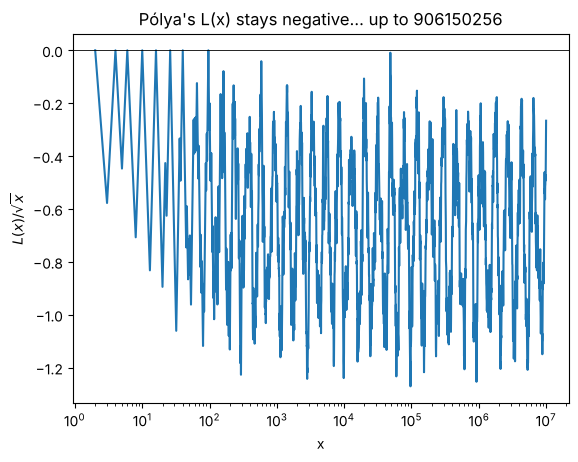

x <= 10^7 with L(x) = 0: 9 values; the first ones [2, 4, 6, 10, 16, 26, 40, 96, 586] the last [40, 96, 586]
identity: 100 = 100


In [6]:
import matplotlib.pyplot as plt
M = 10**7
spf = np.zeros(M + 1, dtype=np.int32)
for p in range(2, int(M**0.5) + 1):
    if spf[p] == 0:
        idx = np.arange(p * p, M + 1, p)
        mask = spf[idx] == 0
        spf[idx[mask]] = p
n = np.arange(M + 1); spf[(spf == 0) & (n >= 2)] = n[(spf == 0) & (n >= 2)]
Omega = np.zeros(M + 1, dtype=np.int8)
for i in range(2, M + 1):
    Omega[i] = Omega[i // spf[i]] + 1
lam = np.where(Omega % 2 == 0, 1, -1); lam[0] = 0
L = np.cumsum(lam)
print("max of L(x) for 2 <= x <= 10^7:", L[2:].max(), " at x =", 2 + int(np.argmax(L[2:])))
xs = np.unique(np.geomspace(2, M, 3000).astype(int))
plt.semilogx(xs, L[xs] / np.sqrt(xs)); plt.axhline(0, color='k', lw=.6)
plt.xlabel("x"); plt.ylabel(r"$L(x)/\sqrt{x}$"); plt.title("Pólya's L(x) stays negative... up to 906150256"); plt.show()
x = 10**4
zeros = np.nonzero(L[2:] == 0)[0] + 2
print("x <= 10^7 with L(x) = 0:", len(zeros), "values; the first ones", zeros[:12].tolist(), "the last", zeros[-3:].tolist())
print("identity:", sum(int(lam[k]) * (x // k) for k in range(1, x + 1)), "=", math.isqrt(x))

The loop over $10^7$ integers takes a while in pure Python; it is the honest way. $L(x)$ comes back to $0$ a number of times (listed above) but never above, and $L(x)/\sqrt x$ wanders between about $-1$ and $0$. Nothing in this picture announces the sign change at $906\,150\,257$; that is the point.

**P7.6.** Build the lattice, reduce, and look for a row of the form $(m,0)$ with $m\in\{0,1\}^n$.

In [7]:
def knapsack_attack(n=20, bits=60, trials=5):
    ok = 0
    for _ in range(trials):
        a = [int(x) for x in rng.integers(1, 2**bits, n, dtype=np.uint64)]
        m = [int(x) for x in rng.integers(0, 2, n)]
        s = sum(mi * ai for mi, ai in zip(m, a))
        N = 2**10
        B = [[1 if i == j else 0 for j in range(n)] + [N * a[i]] for i in range(n)]
        B.append([0] * n + [-N * s])
        Bred = lll_exact(B)
        found = any(row[-1] == 0 and (row[:n] == m or [-x for x in row[:n]] == m) for row in Bred)
        ok += found
    return ok / trials
def lll_exact(b, delta=Fraction(99, 100)):
    # textbook LLL with exact rationals and incremental updates of mu and |b_i*|^2 (Cohen, Algorithm 2.6.3)
    b = [list(map(int, v)) for v in b]; n = len(b)
    Bs, mu = gram_schmidt(b)
    Bn = [sum(x * x for x in v) for v in Bs]
    k = 1
    while k < n:
        for j in range(k - 1, -1, -1):
            q = round(mu[k][j])
            if q:
                b[k] = [x - q * y for x, y in zip(b[k], b[j])]
                for l in range(j): mu[k][l] -= q * mu[j][l]
                mu[k][j] -= q
        if Bn[k] >= (delta - mu[k][k - 1] ** 2) * Bn[k - 1]:
            k += 1
        else:
            b[k], b[k - 1] = b[k - 1], b[k]
            m = mu[k][k - 1]; Bnew = Bn[k] + m * m * Bn[k - 1]
            mu[k][k - 1] = m * Bn[k - 1] / Bnew
            Bn[k] = Bn[k - 1] * Bn[k] / Bnew; Bn[k - 1] = Bnew
            for j in range(k - 1): mu[k - 1][j], mu[k][j] = mu[k][j], mu[k - 1][j]
            for i in range(k + 1, n):
                t = mu[i][k]; mu[i][k] = mu[i][k - 1] - m * t; mu[i][k - 1] = t + mu[k][k - 1] * mu[i][k]
            k = max(k - 1, 1)
    return b
for bits in (14, 18, 22, 30, 45, 60):
    print(f"n=20, a_i < 2^{bits} (density {20/bits:.2f}): success rate {knapsack_attack(20, bits, 4):.2f}")

n=20, a_i < 2^14 (density 1.43): success rate 0.25


n=20, a_i < 2^18 (density 1.11): success rate 0.00


n=20, a_i < 2^22 (density 0.91): success rate 0.25


n=20, a_i < 2^30 (density 0.67): success rate 1.00


n=20, a_i < 2^45 (density 0.44): success rate 1.00


n=20, a_i < 2^60 (density 0.33): success rate 1.00


At low density (large $a_i$) the hidden message is by far the shortest vector of the lattice, and LLL finds it; at high density (small $a_i$) there are many short vectors and the attack fails. For $n=20$ the transition lies between densities $0.67$ and $0.9$, above the $0.6463$ for which Lagarias and Odlyzko (with a stronger lattice oracle) could prove success, because LLL usually does much better than its guarantee. This is how the Merkle–Hellman knapsack cryptosystem was broken in the early 1980s (Shamir, then Lagarias–Odlyzko), and why lattice problems moved from number theory to the centre of cryptography, where today they are the basis of the post-quantum standards. (We used exact rational arithmetic, which is slow; production implementations such as `fplll` use carefully controlled floating point.)